# Research Notebook: Multi-Sensor Pipeline Condition Classification

This notebook contains the experimental workflow for the final-year research project. It is written for **Google Colab** and reads the raw recordings from Google Drive. The raw dataset and intermediate pickle files are not stored in this GitHub repository.

## Research scope

The experiments investigate classification of five conditions in an experimental water-distribution testbed using vibration, acoustic, and dynamic-pressure measurements. This is a laboratory-dataset study; it is not evidence of a deployed real-world pipeline monitoring system.

## Dataset structure recorded by the notebook

- **40 recordings**: two network configurations (BR and LO) × five condition labels × four operating conditions.
- **Five labels**: CC, GL, LC, NL, and OL.
- **Six sensor channels**: A1, A2, H1, H2, P1, and P2.
- **30 seconds per recording** are used for feature construction.
- **Windowing**: 1.0-second windows with a 0.5-second hop, producing 59 windows per recording and 2,360 windows in total.

## Sensor channels

| Channels | Measurement |
|---|---|
| A1, A2 | Accelerometer / vibration |
| H1, H2 | Hydrophone / acoustic |
| P1, P2 | Dynamic pressure |

## Feature representation

The main model input is a tensor with shape **(2360, 6, 16)**: 2,360 windows, six sensor nodes, and 16 features per node. The 16 node features consist of total log spectral power, 12 log spectral-band power fractions, skewness, kurtosis, and crest factor.

The feature-engineering step also computes six pairwise features for each of three same-type sensor pairs (A1–A2, H1–H2, and P1–P2). These pairwise features are saved as `Xc` and are used in the preliminary Random Forest comparison in Step 3. **The later neural-network and graph-model benchmark uses the six-node feature tensor `Xn` (16 features per node), not the `Xc` pairwise feature vector.** Keep this distinction clear when describing the final model.

## Evaluation protocols

- **Test 1 — unseen recordings:** StratifiedGroupKFold keeps windows from an original recording in one fold, preventing windows from the same recording from appearing in both training and test sets.
- **Test 2 — unseen flow condition:** one of the four operating conditions is held out for testing, while the other three are used for training.

The benchmark reports mean accuracy and macro-F1 across folds. Macro-F1 gives equal weight to each class and is not the same as accuracy.

## Noise and GAN experiments

The robustness experiment adds controlled Gaussian noise to the raw test signals at the specified SNR levels. The noise-augmentation experiment adds selected noisy training copies (20 dB and 5 dB) to clean training windows. The conditional-GAN experiment is a separate comparison against clean-only and noise-augmented training; its results should be reported as observed, not described as a consistent improvement.

## Website demo model

The final export step trains a separate GraphSAGE-v2 model on three flow conditions and holds out **0.47 LPS**. It evaluates 590 held-out windows and exports the model plus 60 selected examples for the Streamlit website. The 60-example website score and the 590-window held-out metrics are separate from the cross-validation benchmark results above.

## Before running

1. Open this notebook in Google Colab.
2. Obtain the dataset from the cited dataset source and place it in the expected Google Drive folder, or edit the `ROOT` paths in the cells.
3. Run the cells in order. Later cells depend on files generated by earlier steps in `processed_real`.
4. Do not treat saved cell outputs as a fresh rerun; rerun the relevant cells if you change the dataset, preprocessing, or code.


## Step 1 — Inspect the source dataset

Check the available CSV and RAW files, time axes, sampling rates, sensor coverage, and class-level signal summaries.

In [ ]:
# STEP 1 - DIAGNOSE THE REAL DATASET (paste into ONE new Colab cell and run)
# Uses ONLY the real Mendeley dataset. Stops with an error if it is missing.

import os, re, glob
import numpy as np
import pandas as pd
from google.colab import drive

drive.mount('/content/drive')
ROOT = "/content/drive/MyDrive/FINAL_YEAR_PROJECT/Dataset of Leak Simulations in Experimental Testbed Water Distribution System"
assert os.path.exists(ROOT), "REAL DATASET NOT FOUND - fix the path, do NOT use mock data"

# unzip the 3 sensor zips if CSVs are not there yet
import zipfile
for z in ["Accelerometer.zip", "Hydrophone.zip", "Dynamic Pressure Sensor.zip"]:
    zp = os.path.join(ROOT, z)
    if os.path.exists(zp):
        with zipfile.ZipFile(zp) as f:
            f.extractall(ROOT)

pat = re.compile(r"^(BR|LO)_(CC|GL|LC|NL|OL)_(.+)_([AHP]\d)$")
files = [p for p in glob.glob(os.path.join(ROOT, "**", "*.csv"), recursive=True)
         if pat.match(os.path.splitext(os.path.basename(p))[0])]
print("Matching CSV files:", len(files))
assert len(files) > 0, "No files matched the naming pattern"

# 1) look at ONE file of each sensor type: columns, time axis, sampling rate
seen = set()
for p in sorted(files):
    s = pat.match(os.path.splitext(os.path.basename(p))[0]).group(4)[0]
    if s in seen:
        continue
    seen.add(s)
    df = pd.read_csv(p)
    print("\n---", os.path.basename(p), "---")
    print("columns:", list(df.columns), "| rows:", len(df))
    print(df.head(3).to_string())
    t = df.iloc[:, 0].values.astype(float)
    dt = np.median(np.diff(t))
    print("first col min/max:", t.min(), t.max(), "| median step:", dt)
    print("=> fs if column is SECONDS:", round(1 / dt, 2), "Hz")
    print("=> duration if SECONDS:", round(t[-1] - t[0], 2), "s | if INDEX:", len(df), "samples")

# 2) per-class average signal energy (is there ANY visible difference between classes?)
rows = []
for p in files:
    cfg, typ, cond, sens = pat.match(os.path.splitext(os.path.basename(p))[0]).groups()
    v = pd.read_csv(p).iloc[:, 1].values.astype(float)
    rows.append((cfg, typ, cond, sens, v.std(), np.sqrt(np.mean(v**2))))
d = pd.DataFrame(rows, columns=["cfg", "type", "cond", "sensor", "std", "rms"])
print("\nMean RMS per leak type x sensor:")
print(d.pivot_table(index="type", columns="sensor", values="rms", aggfunc="mean").round(4))
print("\nRecordings per class (config x condition):")
print(d.groupby("type")[["cfg"]].count() // 6)

Mounted at /content/drive
Matching CSV files: 160

--- BR_CC_0.18 LPS_A1.csv ---
columns: ['Sample', 'Value'] | rows: 923488
     Sample     Value
0  0.000000  0.004024
1  0.000039  0.003373
2  0.000078  0.002977
first col min/max: 0.0 36.07371094 | median step: 3.906000000242216e-05
=> fs if column is SECONDS: 25601.64 Hz
=> duration if SECONDS: 36.07 s | if INDEX: 923488 samples

--- BR_CC_0.18 LPS_P1.csv ---
columns: ['Sample', 'Value'] | rows: 943716
     Sample        Value
0  0.000000 -5831.317138
1  0.000039 -5639.000792
2  0.000078 -5441.535304
first col min/max: 0.0 36.86386719 | median step: 3.906000000242216e-05
=> fs if column is SECONDS: 25601.64 Hz
=> duration if SECONDS: 36.86 s | if INDEX: 943716 samples

Mean RMS per leak type x sensor:
sensor      A1      A2         P1        P2
type                                       
CC      0.0044  0.0020  2396.6002  436.7282
GL      0.0052  0.0025  2743.4480  421.5338
LC      0.0043  0.0020  2354.8313  442.2547
NL      0.0084  

In [ ]:
import os, zipfile
ROOT = "/content/drive/MyDrive/FINAL_YEAR_PROJECT/Dataset of Leak Simulations in Experimental Testbed Water Distribution System"
for f in sorted(os.listdir(ROOT)):
    p = os.path.join(ROOT, f)
    print(("FILE  " if os.path.isfile(p) else "FOLDER"), f)

hz = os.path.join(ROOT, "Hydrophone.zip")
if os.path.exists(hz):
    with zipfile.ZipFile(hz) as z:
        names = z.namelist()
        print("\nHydrophone.zip entries:", len(names))
        print(names[:8])
else:
    print("\nNo Hydrophone.zip found")

FOLDER Accelerometer
FILE   Accelerometer.zip
FOLDER Dynamic Pressure Sensor
FILE   Dynamic Pressure Sensor.zip
FOLDER Hydrophone
FILE   Hydrophone.zip
FILE   Python code to convert RAW acoustic data to pandas DataFrame.py

Hydrophone.zip entries: 136
['Hydrophone/', 'Hydrophone/Background Noise/', 'Hydrophone/Background Noise/Background Noise_H1.raw', 'Hydrophone/Background Noise/Background Noise_H2.raw', 'Hydrophone/Branched/', 'Hydrophone/Branched/Circumferential Crack/', 'Hydrophone/Branched/Circumferential Crack/BR_CC_0.18 LPS_N_H1.raw', 'Hydrophone/Branched/Circumferential Crack/BR_CC_0.18 LPS_N_H2.raw']


In [ ]:
import os, zipfile, glob
ROOT = "/content/drive/MyDrive/FINAL_YEAR_PROJECT/Dataset of Leak Simulations in Experimental Testbed Water Distribution System"

# 1) show the authors' conversion script
print(open(os.path.join(ROOT, "Python code to convert RAW acoustic data to pandas DataFrame.py"), errors="ignore").read())

# 2) list all hydrophone entries with sizes
with zipfile.ZipFile(os.path.join(ROOT, "Hydrophone.zip")) as z:
    for i in z.infolist():
        if not i.is_dir():
            print(i.filename, "|", round(i.file_size/1e6, 2), "MB")

#!/usr/bin/env python
# coding: utf-8

# In[ ]:


import os
import pandas as pd
import soundfile as sf
"""
class for reading RAW acoustic reads, whihc returns a time series as two 
datetime and value arrays.
"""
class RAWSource(object):
    def __init__(self, **kwargs):
        super(RAWSource, self).__init__(**kwargs)
    def raw_to_time_series(self, raw_file_path, channels=1, samplerate=8000, 
                           subtype='PCM_32', endian='LITTLE'):
        signal_raw = sf.read(raw_file_path, channels=channels, 
                             samplerate=samplerate, subtype=subtype, 
                             endian=endian)
        signal = signal_raw[0]
        return signal
"""
Function to convert the RAWSource outputs to a pandas Dataframe.
""" 
def read_raw_to_signals(directory):
    raw_reader = RAWSource()
    with os.scandir(directory) as entries:
        ID = []
        S = []
        for entry in entries:
            s = raw_reader.raw_to_time_series(entry)
           

In [ ]:
import os, glob
ROOT = "/content/drive/MyDrive/FINAL_YEAR_PROJECT/Dataset of Leak Simulations in Experimental Testbed Water Distribution System"

print(open(os.path.join(ROOT, "Python code to convert RAW acoustic data to pandas DataFrame.py"), errors="ignore").read())

print("\n=== ACCELEROMETER / PRESSURE condition names (Branched, Circumferential Crack) ===")
for folder in ["Accelerometer", "Dynamic Pressure Sensor"]:
    fs = sorted(glob.glob(os.path.join(ROOT, folder, "**", "BR_CC_*"), recursive=True))
    print(folder, len(fs))
    for f in fs:
        print("  ", os.path.relpath(f, ROOT))

#!/usr/bin/env python
# coding: utf-8

# In[ ]:


import os
import pandas as pd
import soundfile as sf
"""
class for reading RAW acoustic reads, whihc returns a time series as two 
datetime and value arrays.
"""
class RAWSource(object):
    def __init__(self, **kwargs):
        super(RAWSource, self).__init__(**kwargs)
    def raw_to_time_series(self, raw_file_path, channels=1, samplerate=8000, 
                           subtype='PCM_32', endian='LITTLE'):
        signal_raw = sf.read(raw_file_path, channels=channels, 
                             samplerate=samplerate, subtype=subtype, 
                             endian=endian)
        signal = signal_raw[0]
        return signal
"""
Function to convert the RAWSource outputs to a pandas Dataframe.
""" 
def read_raw_to_signals(directory):
    raw_reader = RAWSource()
    with os.scandir(directory) as entries:
        ID = []
        S = []
        for entry in entries:
            s = raw_reader.raw_to_time_series(entry)
           

## Step 2 — Build an initial six-sensor dataset

This earlier baseline extracts 10 time- and frequency-domain features per sensor. It is an exploratory baseline, not the final 16-feature representation.

In [ ]:
# STEP 2 - BUILD REAL 6-SENSOR DATASET + QUICK RANDOM FOREST CHECK
# Paste into ONE Colab cell (after step 1 has run, so Drive is mounted and zips extracted).

import os, re, glob, pickle
import numpy as np
import pandas as pd
from scipy import stats
from scipy.fft import rfft, rfftfreq
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix

ROOT = "/content/drive/MyDrive/FINAL_YEAR_PROJECT/Dataset of Leak Simulations in Experimental Testbed Water Distribution System"
OUT_DIR = "/content/drive/MyDrive/FINAL_YEAR_PROJECT/processed_real"
assert os.path.exists(ROOT), "REAL DATASET NOT FOUND"
os.makedirs(OUT_DIR, exist_ok=True)

SENSORS = ["A1", "A2", "H1", "H2", "P1", "P2"]
CLASSES = ["CC", "GL", "LC", "NL", "OL"]
WIN_S, HOP_S = 1.0, 0.5
HYDRO_FS = 8000            # from the dataset authors' script
HYDRO_MAX = 240000         # authors keep first 240000 samples (30 s)

# ---------- loaders ----------
def load_csv(path):
    df = pd.read_csv(path)
    t = df.iloc[:, 0].values.astype(float)
    v = df.iloc[:, 1].values.astype(float)
    fs = 1.0 / np.median(np.diff(t))
    return v, fs

def load_raw(path):
    # 1 channel, PCM_32, little endian -> int32 scaled to [-1, 1)
    v = np.fromfile(path, dtype="<i4").astype(np.float64) / 2**31
    return v[:HYDRO_MAX], float(HYDRO_FS)

# ---------- find files ----------
pat_csv = re.compile(r"^(BR|LO)_(CC|GL|LC|NL|OL)_(.+)_([AP]\d)$")
pat_raw = re.compile(r"^(BR|LO)_(CC|GL|LC|NL|OL)_(.+?)_(NN|N)_(H\d)$")

groups = {}   # (cfg, type, cond) -> {sensor: (path, kind)}
for p in glob.glob(os.path.join(ROOT, "**", "*.csv"), recursive=True):
    m = pat_csv.match(os.path.splitext(os.path.basename(p))[0])
    if m:
        cfg, typ, cond, s = m.groups()
        groups.setdefault((cfg, typ, cond.strip()), {})[s] = (p, "csv")

for p in glob.glob(os.path.join(ROOT, "**", "*.raw"), recursive=True):
    m = pat_raw.match(os.path.splitext(os.path.basename(p))[0])
    if m:
        cfg, typ, cond, nn, s = m.groups()
        if nn == "N":                      # use the _N version only (see note)
            groups.setdefault((cfg, typ, cond.strip()), {})[s] = (p, "raw")

print("recordings (config x type x condition):", len(groups))
missing = {k: [s for s in SENSORS if s not in v] for k, v in groups.items()}
bad = {k: m for k, m in missing.items() if m}
print("recordings with missing sensors:", len(bad))
for k, m in list(bad.items())[:10]:
    print("  ", k, "missing", m)

# ---------- features ----------
def feats(x, fs):
    x = x[~np.isnan(x)]
    if len(x) < 4:
        return np.zeros(10)
    rms = np.sqrt(np.mean(x**2))
    mag = np.abs(rfft(x)); fr = rfftfreq(len(x), 1.0 / fs)
    dom = fr[np.argmax(mag[1:]) + 1]
    return np.array([x.mean(), x.std(), rms, x.max() - x.min(), stats.skew(x),
                     stats.kurtosis(x), np.max(np.abs(x)) / (rms + 1e-12),
                     dom, np.sum(mag**2), np.sum(fr * mag) / (np.sum(mag) + 1e-12)])

# ---------- build windows ----------
X, y, gid, meta = [], [], [], []
for g, (key, sens) in enumerate(sorted(groups.items())):
    if any(s not in sens for s in SENSORS):
        continue                                   # skip incomplete recordings
    sig = {}
    for s in SENSORS:
        path, kind = sens[s]
        sig[s] = load_csv(path) if kind == "csv" else load_raw(path)
    dur = min(len(v) / fs for v, fs in sig.values())
    n_win = int(np.floor((dur - WIN_S) / HOP_S)) + 1
    for w in range(n_win):
        a, b = w * HOP_S, w * HOP_S + WIN_S
        node = np.zeros((6, 10))
        for i, s in enumerate(SENSORS):
            v, fs = sig[s]
            node[i] = feats(v[int(round(a * fs)):int(round(b * fs))], fs)
        X.append(node); y.append(CLASSES.index(key[1])); gid.append(g)
        meta.append(key)
    print(f"  {key}: usable {dur:.1f}s -> {n_win} windows")

X, y, gid = np.stack(X), np.array(y), np.array(gid)
print("\nX:", X.shape, "| recordings:", len(np.unique(gid)))
print("windows per class:", {c: int((y == i).sum()) for i, c in enumerate(CLASSES)})

with open(os.path.join(OUT_DIR, "dataset_real.pkl"), "wb") as f:
    pickle.dump({"X": X, "y": y, "group_ids": gid, "meta": meta,
                 "sensors": SENSORS, "classes": CLASSES}, f)
print("saved to", OUT_DIR)

# ---------- are hydrophone nodes REAL now? ----------
print("\nMean RMS per class x sensor (H1/H2 must NOT be 0):")
rms = pd.DataFrame(X[:, :, 2], columns=SENSORS); rms["class"] = [CLASSES[i] for i in y]
print(rms.groupby("class").mean().round(5))

# ---------- quick Random Forest check (strict group split) ----------
def run_rf(idx_sensors, label):
    Xf = X[:, idx_sensors, :].reshape(len(X), -1)
    sg = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
    accs, f1s, P, T = [], [], [], []
    for tr, te in sg.split(Xf, y, groups=gid):
        rf = RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1)
        rf.fit(Xf[tr], y[tr]); p = rf.predict(Xf[te])
        accs.append(accuracy_score(y[te], p)); f1s.append(f1_score(y[te], p, average="macro"))
        P += list(p); T += list(y[te])
    print(f"\n[{label}] acc={np.mean(accs):.3f} (+/-{np.std(accs):.3f})  macroF1={np.mean(f1s):.3f}")
    return T, P

run_rf([0, 1, 4, 5], "RF, 4 sensors A1 A2 P1 P2")
T, P = run_rf([0, 1, 2, 3, 4, 5], "RF, all 6 sensors")
print("\nConfusion matrix, all 6 sensors (rows=true, cols=pred), order:", CLASSES)
print(confusion_matrix(T, P))

recordings (config x type x condition): 40
recordings with missing sensors: 0
  ('BR', 'CC', '0.18 LPS'): usable 30.0s -> 59 windows
  ('BR', 'CC', '0.47 LPS'): usable 30.0s -> 59 windows
  ('BR', 'CC', 'ND'): usable 30.0s -> 59 windows
  ('BR', 'CC', 'Transient'): usable 30.0s -> 59 windows
  ('BR', 'GL', '0.18 LPS'): usable 30.0s -> 59 windows
  ('BR', 'GL', '0.47 LPS'): usable 30.0s -> 59 windows
  ('BR', 'GL', 'ND'): usable 30.0s -> 59 windows
  ('BR', 'GL', 'Transient'): usable 30.0s -> 59 windows
  ('BR', 'LC', '0.18 LPS'): usable 30.0s -> 59 windows
  ('BR', 'LC', '0.47 LPS'): usable 30.0s -> 59 windows
  ('BR', 'LC', 'ND'): usable 30.0s -> 59 windows
  ('BR', 'LC', 'Transient'): usable 30.0s -> 59 windows
  ('BR', 'NL', '0.18 LPS'): usable 30.0s -> 59 windows
  ('BR', 'NL', '0.47 LPS'): usable 30.0s -> 59 windows
  ('BR', 'NL', 'ND'): usable 30.0s -> 59 windows
  ('BR', 'NL', 'Transient'): usable 30.0s -> 59 windows
  ('BR', 'OL', '0.18 LPS'): usable 30.0s -> 59 windows
  ('BR'

## Step 3 — Extract the main spectral feature representation

Build the six-node, 16-feature input tensor and compute supplementary pairwise sensor features. The main model pipeline uses the node tensor.

In [ ]:
# STEP 3 - BETTER FEATURES (spectral band energies + cross-sensor relations)
# Self-contained: paste into ONE Colab cell (Drive must be mounted, step 1 done).

import os, re, glob, pickle
import numpy as np
import pandas as pd
from scipy import stats, signal
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix

ROOT = "/content/drive/MyDrive/FINAL_YEAR_PROJECT/Dataset of Leak Simulations in Experimental Testbed Water Distribution System"
OUT_DIR = "/content/drive/MyDrive/FINAL_YEAR_PROJECT/processed_real"
assert os.path.exists(ROOT), "REAL DATASET NOT FOUND"
os.makedirs(OUT_DIR, exist_ok=True)

SENSORS = ["A1", "A2", "H1", "H2", "P1", "P2"]
CLASSES = ["CC", "GL", "LC", "NL", "OL"]
PAIRS = [("A1", "A2"), ("H1", "H2"), ("P1", "P2")]
WIN_S, HOP_S = 1.0, 0.5
N_BANDS = 12

def load_csv(path):
    df = pd.read_csv(path)
    t = df.iloc[:, 0].values.astype(float); v = df.iloc[:, 1].values.astype(float)
    return v, 1.0 / np.median(np.diff(t))

def load_raw(path):
    v = np.fromfile(path, dtype="<i4").astype(np.float64) / 2**31
    return v[:240000], 8000.0

# ---------- find files (same as step 2; hydrophone uses the _N version) ----------
pat_csv = re.compile(r"^(BR|LO)_(CC|GL|LC|NL|OL)_(.+)_([AP]\d)$")
pat_raw = re.compile(r"^(BR|LO)_(CC|GL|LC|NL|OL)_(.+?)_(NN|N)_(H\d)$")
groups = {}
for p in glob.glob(os.path.join(ROOT, "**", "*.csv"), recursive=True):
    m = pat_csv.match(os.path.splitext(os.path.basename(p))[0])
    if m:
        cfg, typ, cond, s = m.groups(); groups.setdefault((cfg, typ, cond.strip()), {})[s] = (p, "csv")
for p in glob.glob(os.path.join(ROOT, "**", "*.raw"), recursive=True):
    m = pat_raw.match(os.path.splitext(os.path.basename(p))[0])
    if m and m.group(4) == "N":
        cfg, typ, cond, nn, s = m.groups(); groups.setdefault((cfg, typ, cond.strip()), {})[s] = (p, "raw")
print("recordings:", len(groups))

# ---------- feature functions ----------
def node_feats(x, fs):
    """16 features: total log-power, 12 log band-shape values, skew, kurtosis, crest."""
    x = x - x.mean()
    f, P = signal.welch(x, fs=fs, nperseg=2048)
    edges = np.geomspace(20, 0.95 * fs / 2, N_BANDS + 1)
    bp = np.array([P[(f >= edges[i]) & (f < edges[i + 1])].sum() for i in range(N_BANDS)])
    bp = bp + 1e-9 * P.sum() + 1e-30
    tot = bp.sum()
    return np.concatenate([[np.log10(tot)], np.log10(bp / tot),
                           [stats.skew(x), stats.kurtosis(x), np.max(np.abs(x)) / (x.std() + 1e-12)]])

def pair_feats(a, b, fs):
    """6 features: xcorr peak, lag (ms), coherence in 4 bands."""
    a = (a - a.mean()) / (a.std() + 1e-12); b = (b - b.mean()) / (b.std() + 1e-12)
    c = signal.correlate(a, b, mode="full", method="fft") / len(a)
    mid, maxlag = len(a) - 1, int(0.05 * fs)
    seg = c[mid - maxlag: mid + maxlag + 1]
    k = int(np.argmax(np.abs(seg)))
    f, Cxy = signal.coherence(a, b, fs=fs, nperseg=2048)
    e = np.geomspace(20, 0.95 * fs / 2, 5)
    coh = [Cxy[(f >= e[i]) & (f < e[i + 1])].mean() for i in range(4)]
    return [abs(seg[k]), (k - maxlag) / fs * 1000.0] + coh

# ---------- build windows ----------
Xn, Xc, y, gid, meta = [], [], [], [], []
for g, (key, sens) in enumerate(sorted(groups.items())):
    if any(s not in sens for s in SENSORS):
        continue
    sig = {s: (load_csv(sens[s][0]) if sens[s][1] == "csv" else load_raw(sens[s][0])) for s in SENSORS}
    dur = min(len(v) / fs for v, fs in sig.values())
    n_win = int(np.floor((dur - WIN_S) / HOP_S)) + 1
    for w in range(n_win):
        a, b = w * HOP_S, w * HOP_S + WIN_S
        seg = {s: sig[s][0][int(round(a * sig[s][1])):int(round(b * sig[s][1]))] for s in SENSORS}
        Xn.append([node_feats(seg[s], sig[s][1]) for s in SENSORS])
        Xc.append(np.concatenate([pair_feats(seg[p], seg[q], sig[p][1]) for p, q in PAIRS]))
        y.append(CLASSES.index(key[1])); gid.append(g); meta.append(key)
    print("done", key)

Xn = np.nan_to_num(np.stack(Xn)); Xc = np.nan_to_num(np.stack(Xc))
y, gid = np.array(y), np.array(gid)
conds = np.array([m[2] for m in meta])
print("\nnode features:", Xn.shape, "| cross features:", Xc.shape)
with open(os.path.join(OUT_DIR, "dataset_v2.pkl"), "wb") as f:
    pickle.dump({"Xn": Xn, "Xc": Xc, "y": y, "group_ids": gid, "conds": conds, "meta": meta,
                 "sensors": SENSORS, "classes": CLASSES, "pairs": PAIRS}, f)
print("saved dataset_v2.pkl")

# ---------- evaluation ----------
def evaluate(F, name, splits, show_cm=False):
    accs, f1s, P, T = [], [], [], []
    for tr, te in splits:
        rf = RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1).fit(F[tr], y[tr])
        p = rf.predict(F[te])
        accs.append(accuracy_score(y[te], p)); f1s.append(f1_score(y[te], p, average="macro"))
        P += list(p); T += list(y[te])
    print(f"  {name:<28} acc={np.mean(accs):.3f} (+/-{np.std(accs):.3f})  macroF1={np.mean(f1s):.3f}")
    if show_cm:
        print("  confusion (rows=true, cols=pred):", CLASSES); print(confusion_matrix(T, P))

F_node = Xn.reshape(len(Xn), -1)
F_all = np.hstack([F_node, Xc])
splits_group = list(StratifiedGroupKFold(5, shuffle=True, random_state=42).split(F_node, y, groups=gid))
splits_cond = [(np.where(conds != c)[0], np.where(conds == c)[0]) for c in np.unique(conds)]

print("\n=== TEST 1: strict group split (unseen recordings) ===")
evaluate(F_node, "spectral node features", splits_group)
evaluate(F_all, "spectral + cross-sensor", splits_group, show_cm=True)
print("\n=== TEST 2: leave-one-flow-condition-out (unseen flow condition) ===")
evaluate(F_node, "spectral node features", splits_cond)
evaluate(F_all, "spectral + cross-sensor", splits_cond, show_cm=True)

recordings: 40
done ('BR', 'CC', '0.18 LPS')
done ('BR', 'CC', '0.47 LPS')
done ('BR', 'CC', 'ND')
done ('BR', 'CC', 'Transient')
done ('BR', 'GL', '0.18 LPS')
done ('BR', 'GL', '0.47 LPS')
done ('BR', 'GL', 'ND')
done ('BR', 'GL', 'Transient')
done ('BR', 'LC', '0.18 LPS')
done ('BR', 'LC', '0.47 LPS')
done ('BR', 'LC', 'ND')
done ('BR', 'LC', 'Transient')
done ('BR', 'NL', '0.18 LPS')
done ('BR', 'NL', '0.47 LPS')
done ('BR', 'NL', 'ND')
done ('BR', 'NL', 'Transient')
done ('BR', 'OL', '0.18 LPS')
done ('BR', 'OL', '0.47 LPS')
done ('BR', 'OL', 'ND')
done ('BR', 'OL', 'Transient')
done ('LO', 'CC', '0.18 LPS')
done ('LO', 'CC', '0.47 LPS')
done ('LO', 'CC', 'ND')
done ('LO', 'CC', 'Transient')
done ('LO', 'GL', '0.18 LPS')
done ('LO', 'GL', '0.47 LPS')
done ('LO', 'GL', 'ND')
done ('LO', 'GL', 'Transient')
done ('LO', 'LC', '0.18 LPS')
done ('LO', 'LC', '0.47 LPS')
done ('LO', 'LC', 'ND')
done ('LO', 'LC', 'Transient')
done ('LO', 'NL', '0.18 LPS')
done ('LO', 'NL', '0.47 LPS')
done 

## Step 4 — Benchmark the first model architectures

Compare initial GNN, CNN, recurrent, fusion, and Random Forest baselines using the two evaluation protocols.

In [ ]:
# STEP 4 - BENCHMARK: GCN / GAT / GraphSAGE vs 1D-CNN / BiLSTM / CNN-LSTM / Fusion-CNN / Random Forest
# Uses dataset_v2.pkl from step 3. Paste into ONE Colab cell and run (about 10-20 min on CPU).
# Same splits, same seed, same epochs for every neural model. Scaling is fitted inside each fold.

import os, time, pickle
import numpy as np
import torch, torch.nn as nn, torch.nn.functional as F
from google.colab import drive
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix

drive.mount("/content/drive")
OUT_DIR = "/content/drive/MyDrive/FINAL_YEAR_PROJECT/processed_real"
d = pickle.load(open(os.path.join(OUT_DIR, "dataset_v2.pkl"), "rb"))
X, y, gid, conds, CLASSES = d["Xn"], d["y"], d["group_ids"], d["conds"], d["classes"]
N, NN, NF = X.shape                    # windows, 6 sensor nodes, 16 features
EPOCHS, SEED, LR, WD, BS = 100, 42, 5e-3, 5e-4, 128
print("data:", X.shape, "| classes:", CLASSES)

# ---------------- GNN layers (dense, fully-connected 6-node sensor graph) ----------------
class GCNLayer(nn.Module):
    def __init__(s, i, o): super().__init__(); s.lin = nn.Linear(i, o)
    def forward(s, x, g): return g[0] @ s.lin(x)                     # D^-1/2 (A+I) D^-1/2 X W

class GATLayer(nn.Module):
    def __init__(s, i, o):
        super().__init__(); s.lin = nn.Linear(i, o, bias=False)
        s.a_src = nn.Linear(o, 1, bias=False); s.a_dst = nn.Linear(o, 1, bias=False)
    def forward(s, x, g):
        h = s.lin(x)
        e = F.leaky_relu(s.a_src(h) + s.a_dst(h).transpose(1, 2), 0.2)   # (B,n,n)
        e = e.masked_fill(g[1] == 0, float("-inf"))
        return torch.softmax(e, -1) @ h                                   # attention-weighted neighbours

class SAGELayer(nn.Module):
    def __init__(s, i, o): super().__init__(); s.ls = nn.Linear(i, o); s.ln = nn.Linear(i, o)
    def forward(s, x, g):
        nei = (g[2] @ x) / g[2].sum(-1, keepdim=True).clamp(min=1)       # mean of neighbours (no self)
        return s.ls(x) + s.ln(nei)

class GNN(nn.Module):
    def __init__(s, layer, h=32, nc=5, p=0.3):
        super().__init__()
        s.l1, s.l2, s.dp, s.out = layer(NF, h), layer(h, h), nn.Dropout(p), nn.Linear(h, nc)
        A = torch.ones(NN, NN)
        s.register_buffer("g0", A / NN); s.register_buffer("g1", A); s.register_buffer("g2", A - torch.eye(NN))
    def forward(s, x):
        g = (s.g0, s.g1, s.g2)
        h = s.dp(F.relu(s.l1(x, g))); h = F.relu(s.l2(h, g))
        return s.out(h.mean(1))                                            # mean-pool nodes -> graph

# ---------------- baselines ----------------
class CNN1D(nn.Module):          # sensors as channels, convolution along the feature axis
    def __init__(s, h=32, nc=5):
        super().__init__(); s.c1 = nn.Conv1d(NN, h, 3, padding=1); s.c2 = nn.Conv1d(h, h, 3, padding=1)
        s.dp = nn.Dropout(0.3); s.out = nn.Linear(h, nc)
    def forward(s, x):
        x = F.relu(s.c2(F.relu(s.c1(x)))).mean(-1); return s.out(s.dp(x))

class BiLSTM(nn.Module):         # sequence over the 6 sensors
    def __init__(s, h=32, nc=5):
        super().__init__(); s.rnn = nn.LSTM(NF, h, batch_first=True, bidirectional=True)
        s.dp = nn.Dropout(0.3); s.out = nn.Linear(2 * h, nc)
    def forward(s, x): return s.out(s.dp(s.rnn(x)[0].mean(1)))

class CNNLSTM(nn.Module):
    def __init__(s, h=32, nc=5):
        super().__init__(); s.c = nn.Conv1d(NF, h, 3, padding=1)
        s.rnn = nn.LSTM(h, h, batch_first=True, bidirectional=True); s.dp = nn.Dropout(0.3); s.out = nn.Linear(2 * h, nc)
    def forward(s, x):
        c = F.relu(s.c(x.permute(0, 2, 1))).permute(0, 2, 1)
        return s.out(s.dp(s.rnn(c)[0].mean(1)))

class FusionCNN(nn.Module):      # per-sensor encoder, then CONCATENATION (the "shallow fusion" baseline)
    def __init__(s, h=16, nc=5):
        super().__init__()
        s.enc = nn.Sequential(nn.Linear(NF, h), nn.ReLU(), nn.Linear(h, h), nn.ReLU())
        s.head = nn.Sequential(nn.Linear(h * NN, 2 * h), nn.ReLU(), nn.Dropout(0.3), nn.Linear(2 * h, nc))
    def forward(s, x): return s.head(s.enc(x).reshape(len(x), -1))

NEURAL = {"GCN": lambda: GNN(GCNLayer), "GAT": lambda: GNN(GATLayer), "GraphSAGE": lambda: GNN(SAGELayer),
          "1D-CNN": CNN1D, "BiLSTM": BiLSTM, "CNN-LSTM": CNNLSTM, "Fusion-CNN": FusionCNN}

# ---------------- training / evaluation ----------------
def fit_eval_nn(make, tr, te, seed):
    torch.manual_seed(seed); np.random.seed(seed)
    mu, sd = X[tr].mean(0, keepdims=True), X[tr].std(0, keepdims=True) + 1e-8     # per (node, feature)
    Xtr = torch.tensor((X[tr] - mu) / sd, dtype=torch.float32)
    Xte = torch.tensor((X[te] - mu) / sd, dtype=torch.float32)
    ytr = torch.tensor(y[tr], dtype=torch.long)
    m = make(); opt = torch.optim.Adam(m.parameters(), lr=LR, weight_decay=WD)
    for _ in range(EPOCHS):
        m.train(); perm = torch.randperm(len(Xtr))
        for i in range(0, len(Xtr), BS):
            idx = perm[i:i + BS]; opt.zero_grad()
            F.cross_entropy(m(Xtr[idx]), ytr[idx]).backward(); opt.step()
    m.eval(); t0 = time.time()
    with torch.no_grad():
        pred = torch.cat([m(Xte[i:i + 256]).argmax(1) for i in range(0, len(Xte), 256)]).numpy()
    ms = (time.time() - t0) / len(Xte) * 1000
    return pred, sum(p.numel() for p in m.parameters()), ms

def fit_eval_rf(tr, te, seed):
    rf = RandomForestClassifier(n_estimators=200, random_state=seed, n_jobs=-1).fit(X[tr].reshape(len(tr), -1), y[tr])
    t0 = time.time(); pred = rf.predict(X[te].reshape(len(te), -1))
    return pred, None, (time.time() - t0) / len(te) * 1000

splits = {
    "TEST 1: unseen recordings (group split)":
        list(StratifiedGroupKFold(5, shuffle=True, random_state=42).split(X.reshape(N, -1), y, groups=gid)),
    "TEST 2: unseen flow condition (leave-one-condition-out)":
        [(np.where(conds != c)[0], np.where(conds == c)[0]) for c in np.unique(conds)],
}

results = {}
for proto, sp in splits.items():
    results[proto] = {}
    for name in list(NEURAL) + ["Random Forest"]:
        accs, f1s, P, T, ms_list, params = [], [], [], [], [], None
        for tr, te in sp:
            pred, params, ms = (fit_eval_rf(tr, te, SEED) if name == "Random Forest"
                                else fit_eval_nn(NEURAL[name], tr, te, SEED))
            accs.append(accuracy_score(y[te], pred)); f1s.append(f1_score(y[te], pred, average="macro"))
            P += list(pred); T += list(y[te]); ms_list.append(ms)
        results[proto][name] = dict(acc=np.mean(accs), acc_sd=np.std(accs), f1=np.mean(f1s), f1_sd=np.std(f1s),
                                    params=params, ms=np.mean(ms_list), cm=confusion_matrix(T, P))
        r = results[proto][name]
        print(f"[{proto[:6]}] {name:<13} acc={r['acc']:.3f}  f1={r['f1']:.3f}")

# ---------------- summary tables ----------------
for proto, res in results.items():
    print("\n" + "=" * 78 + f"\n{proto}\n" + "=" * 78)
    print(f"{'Model':<14}{'Accuracy':<18}{'Macro F1':<18}{'Params':<10}{'ms/sample':<10}")
    for name, r in sorted(res.items(), key=lambda kv: -kv[1]["f1"]):
        print(f"{name:<14}{r['acc']:.3f} +/-{r['acc_sd']:.3f}  {r['f1']:.3f} +/-{r['f1_sd']:.3f}  "
              f"{str(r['params']) if r['params'] else '-':<10}{r['ms']:.4f}")
    best = max(res, key=lambda k: res[k]["f1"])
    print(f"\nConfusion matrix of best model ({best}), order {CLASSES}:\n{res[best]['cm']}")

pickle.dump(results, open(os.path.join(OUT_DIR, "benchmark_results_v1.pkl"), "wb"))
print("\nsaved benchmark_results_v1.pkl")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
data: (2360, 6, 16) | classes: ['CC', 'GL', 'LC', 'NL', 'OL']
[TEST 1] GCN           acc=0.522  f1=0.468
[TEST 1] GAT           acc=0.488  f1=0.431
[TEST 1] GraphSAGE     acc=0.665  f1=0.597
[TEST 1] 1D-CNN        acc=0.694  f1=0.610
[TEST 1] BiLSTM        acc=0.670  f1=0.612
[TEST 1] CNN-LSTM      acc=0.792  f1=0.701
[TEST 1] Fusion-CNN    acc=0.759  f1=0.683
[TEST 1] Random Forest acc=0.695  f1=0.633
[TEST 2] GCN           acc=0.650  f1=0.636
[TEST 2] GAT           acc=0.569  f1=0.550
[TEST 2] GraphSAGE     acc=0.721  f1=0.714
[TEST 2] 1D-CNN        acc=0.782  f1=0.778
[TEST 2] BiLSTM        acc=0.759  f1=0.749
[TEST 2] CNN-LSTM      acc=0.837  f1=0.826
[TEST 2] Fusion-CNN    acc=0.879  f1=0.870
[TEST 2] Random Forest acc=0.895  f1=0.893

TEST 1: unseen recordings (group split)
Model         Accuracy          Macro F1          Params    ms/sample 
CNN-LSTM 

## Step 5 — Compare the revised graph architectures

Evaluate sensor-specific encoders, learned sensor relationships, and the GraphSAGE-v2 architecture. The learned edge matrix trained on all data is for interpretation only, not a held-out performance estimate.

In [ ]:
# STEP 5 - GNN v2: keep sensor identity (per-sensor encoder), learned edges, concat readout
# Needs dataset_v2.pkl (step 3) and benchmark_results_v1.pkl (step 4). Same splits / seed / epochs as step 4.
# Paste into ONE Colab cell and run (about 10-15 min on CPU).

import os, time, pickle
import numpy as np
import torch, torch.nn as nn, torch.nn.functional as F
from google.colab import drive
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix

drive.mount("/content/drive")
OUT_DIR = "/content/drive/MyDrive/FINAL_YEAR_PROJECT/processed_real"
d = pickle.load(open(os.path.join(OUT_DIR, "dataset_v2.pkl"), "rb"))
X, y, gid, conds, CLASSES, SENSORS = d["Xn"], d["y"], d["group_ids"], d["conds"], d["classes"], d["sensors"]
N, NN, NF = X.shape
EPOCHS, SEED, LR, WD, BS = 100, 42, 5e-3, 5e-4, 128      # identical to step 4

# ---------- building blocks ----------
class NodeEncoder(nn.Module):
    """Separate (sensor-specific) linear layer for each of the 6 nodes -> keeps sensor identity."""
    def __init__(s, h):
        super().__init__()
        s.W = nn.Parameter(torch.randn(NN, NF, h) / np.sqrt(NF)); s.b = nn.Parameter(torch.zeros(NN, h))
    def forward(s, x): return F.relu(torch.einsum("bnf,nfh->bnh", x, s.W) + s.b)

class GCN2(nn.Module):
    """mode: 'learned' (learnable edge weights), 'full' (uniform), 'identity' (NO graph, ablation)."""
    def __init__(s, mode, h=32, nc=5, p=0.3):
        super().__init__(); s.mode = mode
        s.enc, s.l1, s.l2 = NodeEncoder(h), nn.Linear(h, h), nn.Linear(h, h)
        s.L = nn.Parameter(2.0 * torch.eye(NN))                 # starts self-heavy, then learns edges
        s.dp, s.out = nn.Dropout(p), nn.Linear(NN * h, nc)
    def adj(s):
        if s.mode == "identity": return torch.eye(NN)
        if s.mode == "full": return torch.ones(NN, NN) / NN
        return torch.softmax(s.L, -1)
    def forward(s, x):
        A = s.adj(); h = s.enc(x)
        h = s.dp(F.relu(A @ s.l1(h))); h = F.relu(A @ s.l2(h))
        return s.out(s.dp(h.reshape(len(x), -1)))

class GAT2(nn.Module):
    def __init__(s, h=32, nc=5, p=0.3):
        super().__init__(); s.enc = NodeEncoder(h)
        s.z1, s.z2 = nn.Linear(h, h, bias=False), nn.Linear(h, h, bias=False)
        s.s1, s.d1, s.s2, s.d2 = [nn.Linear(h, 1, bias=False) for _ in range(4)]
        s.dp, s.out = nn.Dropout(p), nn.Linear(NN * h, nc)
    @staticmethod
    def att(z, a_s, a_d):
        e = F.leaky_relu(a_s(z) + a_d(z).transpose(1, 2), 0.2)
        return torch.softmax(e, -1) @ z
    def forward(s, x):
        h = s.enc(x)
        h = s.dp(F.relu(s.att(s.z1(h), s.s1, s.d1))); h = F.relu(s.att(s.z2(h), s.s2, s.d2))
        return s.out(s.dp(h.reshape(len(x), -1)))

class SAGE2(nn.Module):
    def __init__(s, h=32, nc=5, p=0.3):
        super().__init__(); s.enc = NodeEncoder(h)
        s.ls1, s.ln1, s.ls2, s.ln2 = [nn.Linear(h, h) for _ in range(4)]
        s.L = nn.Parameter(torch.zeros(NN, NN)); s.dp, s.out = nn.Dropout(p), nn.Linear(NN * h, nc)
    def forward(s, x):
        A = torch.softmax(s.L.masked_fill(torch.eye(NN, dtype=torch.bool), float("-inf")), -1)   # learned, no self
        h = s.enc(x)
        h = s.dp(F.relu(s.ls1(h) + s.ln1(A @ h))); h = F.relu(s.ls2(h) + s.ln2(A @ h))
        return s.out(s.dp(h.reshape(len(x), -1)))

MODELS = {"GCN-v2 (learned edges)": lambda: GCN2("learned"),
          "GCN-v2 (uniform edges)": lambda: GCN2("full"),
          "No-graph ablation": lambda: GCN2("identity"),
          "GAT-v2": GAT2, "GraphSAGE-v2": SAGE2}

# ---------- training / evaluation (same as step 4) ----------
def fit_eval(make, tr, te, seed):
    torch.manual_seed(seed); np.random.seed(seed)
    mu, sd = X[tr].mean(0, keepdims=True), X[tr].std(0, keepdims=True) + 1e-8
    Xtr = torch.tensor((X[tr] - mu) / sd, dtype=torch.float32); Xte = torch.tensor((X[te] - mu) / sd, dtype=torch.float32)
    ytr = torch.tensor(y[tr], dtype=torch.long)
    m = make(); opt = torch.optim.Adam(m.parameters(), lr=LR, weight_decay=WD)
    for _ in range(EPOCHS):
        m.train(); perm = torch.randperm(len(Xtr))
        for i in range(0, len(Xtr), BS):
            idx = perm[i:i + BS]; opt.zero_grad(); F.cross_entropy(m(Xtr[idx]), ytr[idx]).backward(); opt.step()
    m.eval(); t0 = time.time()
    with torch.no_grad():
        pred = torch.cat([m(Xte[i:i + 256]).argmax(1) for i in range(0, len(Xte), 256)]).numpy()
    return pred, sum(p.numel() for p in m.parameters()), (time.time() - t0) / len(Xte) * 1000

splits = {
    "TEST 1: unseen recordings (group split)":
        list(StratifiedGroupKFold(5, shuffle=True, random_state=42).split(X.reshape(N, -1), y, groups=gid)),
    "TEST 2: unseen flow condition (leave-one-condition-out)":
        [(np.where(conds != c)[0], np.where(conds == c)[0]) for c in np.unique(conds)],
}
old = pickle.load(open(os.path.join(OUT_DIR, "benchmark_results_v1.pkl"), "rb"))

results = {}
for proto, sp in splits.items():
    results[proto] = {}
    for name, make in MODELS.items():
        accs, f1s, P, T, mss, params = [], [], [], [], [], None
        for tr, te in sp:
            pred, params, ms = fit_eval(make, tr, te, SEED)
            accs.append(accuracy_score(y[te], pred)); f1s.append(f1_score(y[te], pred, average="macro"))
            P += list(pred); T += list(y[te]); mss.append(ms)
        results[proto][name] = dict(acc=np.mean(accs), acc_sd=np.std(accs), f1=np.mean(f1s), f1_sd=np.std(f1s),
                                    params=params, ms=np.mean(mss), cm=confusion_matrix(T, P))
        print(f"[{proto[:6]}] {name:<24} acc={np.mean(accs):.3f}  f1={np.mean(f1s):.3f}")

# ---------- combined tables (v1 results + new v2 models) ----------
for proto in results:
    comb = {**{k + " (v1)": v for k, v in old[proto].items() if k in ("GCN", "GAT", "GraphSAGE")},
            **{k: v for k, v in old[proto].items() if k not in ("GCN", "GAT", "GraphSAGE")},
            **results[proto]}
    print("\n" + "=" * 86 + f"\n{proto}\n" + "=" * 86)
    print(f"{'Model':<26}{'Accuracy':<18}{'Macro F1':<18}{'Params':<9}{'ms/sample'}")
    for name, r in sorted(comb.items(), key=lambda kv: -kv[1]["f1"]):
        print(f"{name:<26}{r['acc']:.3f} +/-{r['acc_sd']:.3f}  {r['f1']:.3f} +/-{r['f1_sd']:.3f}  "
              f"{str(r['params']) if r['params'] else '-':<9}{r['ms']:.4f}")

# ---------- learned sensor-to-sensor edge weights (interpretation only; trained on ALL data) ----------
torch.manual_seed(SEED)
allidx = np.arange(N)
mu, sd = X.mean(0, keepdims=True), X.std(0, keepdims=True) + 1e-8
Xt = torch.tensor((X - mu) / sd, dtype=torch.float32); yt = torch.tensor(y, dtype=torch.long)
m = GCN2("learned"); opt = torch.optim.Adam(m.parameters(), lr=LR, weight_decay=WD)
for _ in range(EPOCHS):
    m.train(); perm = torch.randperm(N)
    for i in range(0, N, BS):
        idx = perm[i:i + BS]; opt.zero_grad(); F.cross_entropy(m(Xt[idx]), yt[idx]).backward(); opt.step()
print("\nLearned edge weights (row = receiving sensor, col = sending sensor), order", SENSORS)
print(np.round(m.adj().detach().numpy(), 2))

pickle.dump(results, open(os.path.join(OUT_DIR, "benchmark_results_v2.pkl"), "wb"))
print("\nsaved benchmark_results_v2.pkl")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
[TEST 1] GCN-v2 (learned edges)   acc=0.813  f1=0.729
[TEST 1] GCN-v2 (uniform edges)   acc=0.805  f1=0.724
[TEST 1] No-graph ablation        acc=0.814  f1=0.708
[TEST 1] GAT-v2                   acc=0.681  f1=0.597
[TEST 1] GraphSAGE-v2             acc=0.860  f1=0.820
[TEST 2] GCN-v2 (learned edges)   acc=0.871  f1=0.856
[TEST 2] GCN-v2 (uniform edges)   acc=0.842  f1=0.825
[TEST 2] No-graph ablation        acc=0.886  f1=0.882
[TEST 2] GAT-v2                   acc=0.806  f1=0.794
[TEST 2] GraphSAGE-v2             acc=0.863  f1=0.859

TEST 1: unseen recordings (group split)
Model                     Accuracy          Macro F1          Params   ms/sample
GraphSAGE-v2              0.860 +/-0.102  0.820 +/-0.144  8489     0.0059
GCN-v2 (learned edges)    0.813 +/-0.096  0.729 +/-0.125  6377     0.0039
GCN-v2 (uniform edges)    0.805 +/-0.094  0.724 +/-0.088  637

## Step 6 — Test robustness to added signal noise

Models are trained on clean training windows and evaluated on noisy test signals at multiple SNR levels.

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
noisy features done: ('BR', 'CC', '0.18 LPS')
noisy features done: ('BR', 'CC', '0.47 LPS')
noisy features done: ('BR', 'CC', 'ND')
noisy features done: ('BR', 'CC', 'Transient')
noisy features done: ('BR', 'GL', '0.18 LPS')
noisy features done: ('BR', 'GL', '0.47 LPS')
noisy features done: ('BR', 'GL', 'ND')
noisy features done: ('BR', 'GL', 'Transient')
noisy features done: ('BR', 'LC', '0.18 LPS')
noisy features done: ('BR', 'LC', '0.47 LPS')
noisy features done: ('BR', 'LC', 'ND')
noisy features done: ('BR', 'LC', 'Transient')
noisy features done: ('BR', 'NL', '0.18 LPS')
noisy features done: ('BR', 'NL', '0.47 LPS')
noisy features done: ('BR', 'NL', 'ND')
noisy features done: ('BR', 'NL', 'Transient')
noisy features done: ('BR', 'OL', '0.18 LPS')
noisy features done: ('BR', 'OL', '0.47 LPS')
noisy features done: ('BR', 'OL', 'ND')
noisy features done: ('

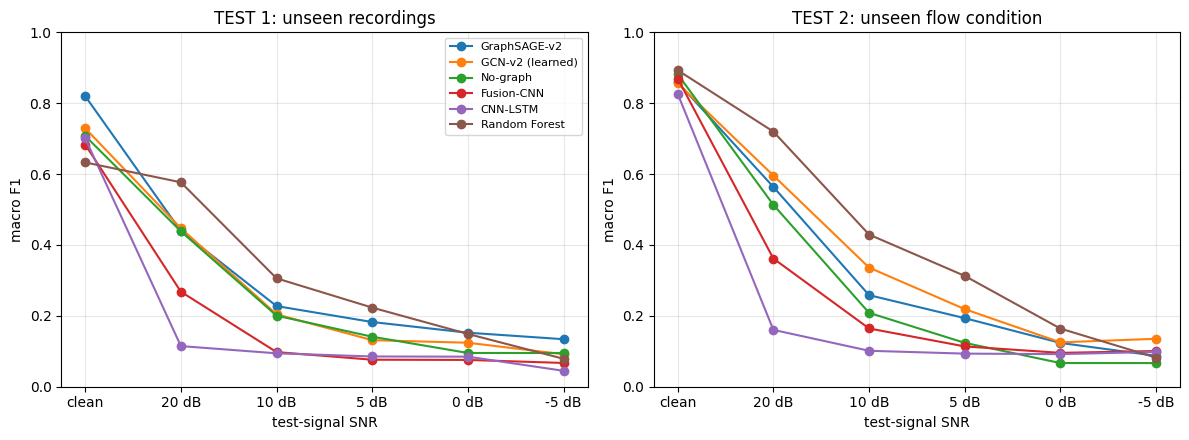


saved snr_results.pkl and snr_robustness.png


In [ ]:
# STEP 6 - SNR SWEEP (noise injected into RAW test signals, models trained on CLEAN data)
# Needs dataset_v2.pkl (step 3). Paste into ONE Colab cell. About 25-35 min on CPU.
# Part A builds noisy features once and saves them to Drive (skipped on re-run). Part B evaluates the models.

import os, re, glob, time, pickle
import numpy as np
import pandas as pd
import torch, torch.nn as nn, torch.nn.functional as F
from scipy import stats, signal
from google.colab import drive
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score, accuracy_score
import matplotlib.pyplot as plt

drive.mount("/content/drive")
ROOT = "/content/drive/MyDrive/FINAL_YEAR_PROJECT/Dataset of Leak Simulations in Experimental Testbed Water Distribution System"
OUT_DIR = "/content/drive/MyDrive/FINAL_YEAR_PROJECT/processed_real"
d = pickle.load(open(os.path.join(OUT_DIR, "dataset_v2.pkl"), "rb"))
X, y, gid, conds, meta, CLASSES, SENSORS = d["Xn"], d["y"], d["group_ids"], d["conds"], d["meta"], d["classes"], d["sensors"]
N, NN, NF = X.shape
SNRS = [20, 10, 5, 0, -5]
LEVELS = ["clean"] + SNRS
N_BANDS, WIN_S, HOP_S = 12, 1.0, 0.5
EPOCHS, SEED, LR, WD, BS = 100, 42, 5e-3, 5e-4, 128

# =============== PART A: noisy features ===============
noisy_path = os.path.join(OUT_DIR, "dataset_v2_noisy.pkl")
if os.path.exists(noisy_path):
    Xnoisy = pickle.load(open(noisy_path, "rb"))
    print("loaded noisy features from Drive")
else:
    def load_csv(p):
        df = pd.read_csv(p); t = df.iloc[:, 0].values.astype(float)
        return df.iloc[:, 1].values.astype(float), 1.0 / np.median(np.diff(t))
    def load_raw(p):
        return (np.fromfile(p, dtype="<i4").astype(np.float64) / 2**31)[:240000], 8000.0

    pat_csv = re.compile(r"^(BR|LO)_(CC|GL|LC|NL|OL)_(.+)_([AP]\d)$")
    pat_raw = re.compile(r"^(BR|LO)_(CC|GL|LC|NL|OL)_(.+?)_(NN|N)_(H\d)$")
    groups = {}
    for p in glob.glob(os.path.join(ROOT, "**", "*.csv"), recursive=True):
        m = pat_csv.match(os.path.splitext(os.path.basename(p))[0])
        if m:
            cfg, typ, cond, s = m.groups(); groups.setdefault((cfg, typ, cond.strip()), {})[s] = (p, "csv")
    for p in glob.glob(os.path.join(ROOT, "**", "*.raw"), recursive=True):
        m = pat_raw.match(os.path.splitext(os.path.basename(p))[0])
        if m and m.group(4) == "N":
            cfg, typ, cond, nn_, s = m.groups(); groups.setdefault((cfg, typ, cond.strip()), {})[s] = (p, "raw")

    def node_feats(x, fs):                      # identical to step 3
        x = x - x.mean()
        f, P = signal.welch(x, fs=fs, nperseg=2048)
        edges = np.geomspace(20, 0.95 * fs / 2, N_BANDS + 1)
        bp = np.array([P[(f >= edges[i]) & (f < edges[i + 1])].sum() for i in range(N_BANDS)])
        bp = bp + 1e-9 * P.sum() + 1e-30; tot = bp.sum()
        return np.concatenate([[np.log10(tot)], np.log10(bp / tot),
                               [stats.skew(x), stats.kurtosis(x), np.max(np.abs(x)) / (x.std() + 1e-12)]])

    rng = np.random.default_rng(0)
    def add_noise(x, snr_db):                   # SNR = 10 log10(P_signal / P_noise), P_signal = AC power of the window
        pn = np.var(x) / (10 ** (snr_db / 10))
        return x + rng.normal(0.0, np.sqrt(pn), size=x.shape)

    Xnoisy = {s: [] for s in SNRS}; meta_chk = []
    for key, sens in sorted(groups.items()):
        if any(s not in sens for s in SENSORS):
            continue
        sig = {s: (load_csv(sens[s][0]) if sens[s][1] == "csv" else load_raw(sens[s][0])) for s in SENSORS}
        dur = min(len(v) / fs for v, fs in sig.values())
        for w in range(int(np.floor((dur - WIN_S) / HOP_S)) + 1):
            a, b = w * HOP_S, w * HOP_S + WIN_S
            seg = {s: sig[s][0][int(round(a * sig[s][1])):int(round(b * sig[s][1]))] for s in SENSORS}
            for snr in SNRS:
                Xnoisy[snr].append([node_feats(add_noise(seg[s], snr), sig[s][1]) for s in SENSORS])
            meta_chk.append(key)
        print("noisy features done:", key)
    assert meta_chk == list(meta), "window order differs from dataset_v2 - do not continue"
    Xnoisy = {s: np.nan_to_num(np.stack(v)) for s, v in Xnoisy.items()}
    pickle.dump(Xnoisy, open(noisy_path, "wb")); print("saved", noisy_path)

FEATS = {"clean": X, **Xnoisy}

# =============== PART B: models ===============
class NodeEncoder(nn.Module):
    def __init__(s, h):
        super().__init__(); s.W = nn.Parameter(torch.randn(NN, NF, h) / np.sqrt(NF)); s.b = nn.Parameter(torch.zeros(NN, h))
    def forward(s, x): return F.relu(torch.einsum("bnf,nfh->bnh", x, s.W) + s.b)

class GCN2(nn.Module):
    def __init__(s, mode, h=32, nc=5, p=0.3):
        super().__init__(); s.mode = mode
        s.enc, s.l1, s.l2 = NodeEncoder(h), nn.Linear(h, h), nn.Linear(h, h)
        s.L = nn.Parameter(2.0 * torch.eye(NN)); s.dp, s.out = nn.Dropout(p), nn.Linear(NN * h, nc)
    def adj(s): return torch.eye(NN) if s.mode == "identity" else torch.softmax(s.L, -1)
    def forward(s, x):
        A = s.adj(); h = s.enc(x)
        h = s.dp(F.relu(A @ s.l1(h))); h = F.relu(A @ s.l2(h))
        return s.out(s.dp(h.reshape(len(x), -1)))

class SAGE2(nn.Module):
    def __init__(s, h=32, nc=5, p=0.3):
        super().__init__(); s.enc = NodeEncoder(h)
        s.ls1, s.ln1, s.ls2, s.ln2 = [nn.Linear(h, h) for _ in range(4)]
        s.L = nn.Parameter(torch.zeros(NN, NN)); s.dp, s.out = nn.Dropout(p), nn.Linear(NN * h, nc)
    def forward(s, x):
        A = torch.softmax(s.L.masked_fill(torch.eye(NN, dtype=torch.bool), float("-inf")), -1)
        h = s.enc(x)
        h = s.dp(F.relu(s.ls1(h) + s.ln1(A @ h))); h = F.relu(s.ls2(h) + s.ln2(A @ h))
        return s.out(s.dp(h.reshape(len(x), -1)))

class FusionCNN(nn.Module):
    def __init__(s, h=16, nc=5):
        super().__init__()
        s.enc = nn.Sequential(nn.Linear(NF, h), nn.ReLU(), nn.Linear(h, h), nn.ReLU())
        s.head = nn.Sequential(nn.Linear(h * NN, 2 * h), nn.ReLU(), nn.Dropout(0.3), nn.Linear(2 * h, nc))
    def forward(s, x): return s.head(s.enc(x).reshape(len(x), -1))

class CNNLSTM(nn.Module):
    def __init__(s, h=32, nc=5):
        super().__init__(); s.c = nn.Conv1d(NF, h, 3, padding=1)
        s.rnn = nn.LSTM(h, h, batch_first=True, bidirectional=True); s.dp = nn.Dropout(0.3); s.out = nn.Linear(2 * h, nc)
    def forward(s, x):
        c = F.relu(s.c(x.permute(0, 2, 1))).permute(0, 2, 1)
        return s.out(s.dp(s.rnn(c)[0].mean(1)))

MODELS = {"GraphSAGE-v2": SAGE2, "GCN-v2 (learned)": lambda: GCN2("learned"), "No-graph": lambda: GCN2("identity"),
          "Fusion-CNN": FusionCNN, "CNN-LSTM": CNNLSTM, "Random Forest": None}

def train_nn(make, tr):
    torch.manual_seed(SEED); np.random.seed(SEED)
    mu, sd = X[tr].mean(0, keepdims=True), X[tr].std(0, keepdims=True) + 1e-8
    Xtr = torch.tensor((X[tr] - mu) / sd, dtype=torch.float32); ytr = torch.tensor(y[tr], dtype=torch.long)
    m = make(); opt = torch.optim.Adam(m.parameters(), lr=LR, weight_decay=WD)
    for _ in range(EPOCHS):
        m.train(); perm = torch.randperm(len(Xtr))
        for i in range(0, len(Xtr), BS):
            idx = perm[i:i + BS]; opt.zero_grad(); F.cross_entropy(m(Xtr[idx]), ytr[idx]).backward(); opt.step()
    return m.eval(), mu, sd

def predict_nn(m, mu, sd, Xs):
    Xt = torch.tensor((Xs - mu) / sd, dtype=torch.float32)
    with torch.no_grad():
        return torch.cat([m(Xt[i:i + 256]).argmax(1) for i in range(0, len(Xt), 256)]).numpy()

splits = {
    "TEST 1: unseen recordings": list(StratifiedGroupKFold(5, shuffle=True, random_state=42).split(X.reshape(N, -1), y, groups=gid)),
    "TEST 2: unseen flow condition": [(np.where(conds != c)[0], np.where(conds == c)[0]) for c in np.unique(conds)],
}

res = {p: {m: {lv: [] for lv in LEVELS} for m in MODELS} for p in splits}
for proto, sp in splits.items():
    for name, make in MODELS.items():
        for tr, te in sp:
            if name == "Random Forest":
                rf = RandomForestClassifier(n_estimators=200, random_state=SEED, n_jobs=-1).fit(X[tr].reshape(len(tr), -1), y[tr])
                pred_fn = lambda Xs, rf=rf: rf.predict(Xs.reshape(len(Xs), -1))
            else:
                m, mu, sd = train_nn(make, tr)
                pred_fn = lambda Xs, m=m, mu=mu, sd=sd: predict_nn(m, mu, sd, Xs)
            for lv in LEVELS:
                res[proto][name][lv].append(f1_score(y[te], pred_fn(FEATS[lv][te]), average="macro"))
        print(f"[{proto[:6]}] {name:<18}", " ".join(f"{lv}:{np.mean(res[proto][name][lv]):.2f}" for lv in LEVELS))

# =============== tables + plot ===============
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, (proto, r) in zip(axes, res.items()):
    print("\n" + "=" * 80 + f"\n{proto}  (macro F1, mean over folds; models trained on clean data)\n" + "=" * 80)
    print(f"{'Model':<20}" + "".join(f"{str(lv):>9}" for lv in LEVELS))
    for name in MODELS:
        means = [np.mean(r[name][lv]) for lv in LEVELS]
        print(f"{name:<20}" + "".join(f"{v:>9.3f}" for v in means))
        ax.plot(range(len(LEVELS)), means, marker="o", label=name)
    ax.set_xticks(range(len(LEVELS))); ax.set_xticklabels(["clean"] + [f"{s} dB" for s in SNRS])
    ax.set_xlabel("test-signal SNR"); ax.set_ylabel("macro F1"); ax.set_title(proto); ax.grid(alpha=.3); ax.set_ylim(0, 1)
axes[0].legend(fontsize=8)
plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, "snr_robustness.png"), dpi=200); plt.show()
pickle.dump(res, open(os.path.join(OUT_DIR, "snr_results.pkl"), "wb"))
print("\nsaved snr_results.pkl and snr_robustness.png")


## Step 7 — Evaluate noise-augmented training

Training includes clean windows plus selected noisy copies (20 dB and 5 dB). Compare the clean and noisy test performance with the clean-only experiment.

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
training levels: clean + [20, 5] dB | epochs: 33
[TEST 1] GraphSAGE-v2       clean:0.69 20:0.67 10:0.65 5:0.63 0:0.55 -5:0.38
[TEST 1] GCN-v2 (learned)   clean:0.64 20:0.65 10:0.65 5:0.63 0:0.57 -5:0.37
[TEST 1] No-graph           clean:0.68 20:0.67 10:0.67 5:0.63 0:0.56 -5:0.34
[TEST 1] Fusion-CNN         clean:0.65 20:0.66 10:0.63 5:0.63 0:0.56 -5:0.45
[TEST 1] CNN-LSTM           clean:0.66 20:0.69 10:0.68 5:0.65 0:0.58 -5:0.32
[TEST 1] Random Forest      clean:0.65 20:0.63 10:0.61 5:0.63 0:0.29 -5:0.12
[TEST 2] GraphSAGE-v2       clean:0.88 20:0.89 10:0.84 5:0.85 0:0.79 -5:0.48
[TEST 2] GCN-v2 (learned)   clean:0.83 20:0.84 10:0.83 5:0.82 0:0.70 -5:0.47
[TEST 2] No-graph           clean:0.84 20:0.86 10:0.81 5:0.78 0:0.67 -5:0.44
[TEST 2] Fusion-CNN         clean:0.85 20:0.87 10:0.86 5:0.84 0:0.76 -5:0.57
[TEST 2] CNN-LSTM           clean:0.76 20:0.78 10:0.

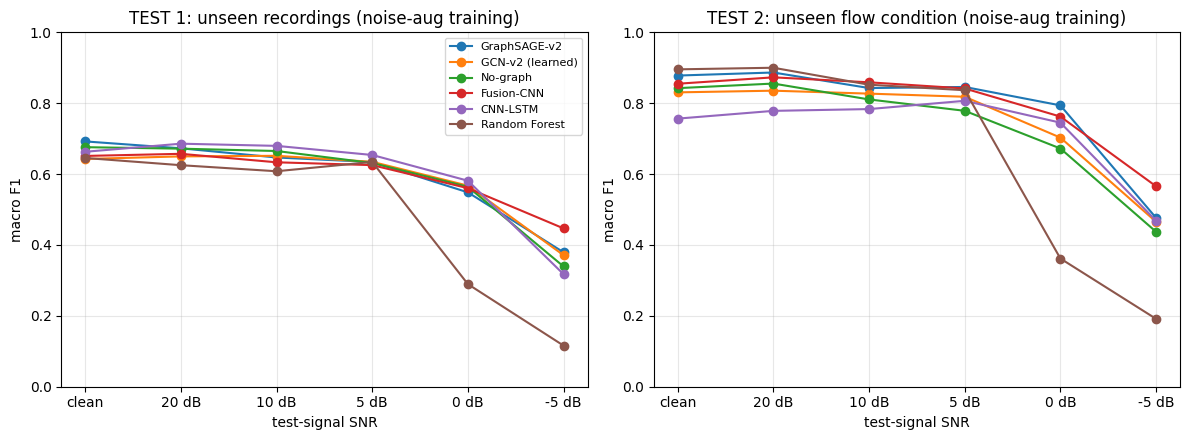


saved snr_results_aug.pkl and snr_robustness_aug.png


In [ ]:
# STEP 7 - NOISE-AUGMENTED TRAINING (baseline that the GAN must beat later)
# Train on clean + noisy copies at 20 dB and 5 dB ONLY. Test at clean, 20, 10, 5, 0, -5 dB.
# 10 and 0 dB are UNSEEN in-between levels; -5 dB is beyond anything seen in training.
# Needs dataset_v2.pkl, dataset_v2_noisy.pkl (step 6) and snr_results.pkl (step 6). About 15-20 min on CPU.

import os, pickle
import numpy as np
import torch, torch.nn as nn, torch.nn.functional as F
from google.colab import drive
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score
import matplotlib.pyplot as plt

drive.mount("/content/drive")
OUT_DIR = "/content/drive/MyDrive/FINAL_YEAR_PROJECT/processed_real"
d = pickle.load(open(os.path.join(OUT_DIR, "dataset_v2.pkl"), "rb"))
X, y, gid, conds = d["Xn"], d["y"], d["group_ids"], d["conds"]
Xnoisy = pickle.load(open(os.path.join(OUT_DIR, "dataset_v2_noisy.pkl"), "rb"))
clean_res = pickle.load(open(os.path.join(OUT_DIR, "snr_results.pkl"), "rb"))
N, NN, NF = X.shape
SNRS = [20, 10, 5, 0, -5]; LEVELS = ["clean"] + SNRS
AUG = [20, 5]                                  # levels used for training augmentation
FEATS = {"clean": X, **Xnoisy}
SEED, LR, WD, BS = 42, 5e-3, 5e-4, 128
EPOCHS_AUG = 33                                # data is 3x bigger -> about the same number of updates as 100 clean epochs
print("training levels: clean +", AUG, "dB | epochs:", EPOCHS_AUG)

# ---------- models (same as step 6) ----------
class NodeEncoder(nn.Module):
    def __init__(s, h):
        super().__init__(); s.W = nn.Parameter(torch.randn(NN, NF, h) / np.sqrt(NF)); s.b = nn.Parameter(torch.zeros(NN, h))
    def forward(s, x): return F.relu(torch.einsum("bnf,nfh->bnh", x, s.W) + s.b)

class GCN2(nn.Module):
    def __init__(s, mode, h=32, nc=5, p=0.3):
        super().__init__(); s.mode = mode
        s.enc, s.l1, s.l2 = NodeEncoder(h), nn.Linear(h, h), nn.Linear(h, h)
        s.L = nn.Parameter(2.0 * torch.eye(NN)); s.dp, s.out = nn.Dropout(p), nn.Linear(NN * h, nc)
    def adj(s): return torch.eye(NN) if s.mode == "identity" else torch.softmax(s.L, -1)
    def forward(s, x):
        A = s.adj(); h = s.enc(x)
        h = s.dp(F.relu(A @ s.l1(h))); h = F.relu(A @ s.l2(h))
        return s.out(s.dp(h.reshape(len(x), -1)))

class SAGE2(nn.Module):
    def __init__(s, h=32, nc=5, p=0.3):
        super().__init__(); s.enc = NodeEncoder(h)
        s.ls1, s.ln1, s.ls2, s.ln2 = [nn.Linear(h, h) for _ in range(4)]
        s.L = nn.Parameter(torch.zeros(NN, NN)); s.dp, s.out = nn.Dropout(p), nn.Linear(NN * h, nc)
    def forward(s, x):
        A = torch.softmax(s.L.masked_fill(torch.eye(NN, dtype=torch.bool), float("-inf")), -1)
        h = s.enc(x)
        h = s.dp(F.relu(s.ls1(h) + s.ln1(A @ h))); h = F.relu(s.ls2(h) + s.ln2(A @ h))
        return s.out(s.dp(h.reshape(len(x), -1)))

class FusionCNN(nn.Module):
    def __init__(s, h=16, nc=5):
        super().__init__()
        s.enc = nn.Sequential(nn.Linear(NF, h), nn.ReLU(), nn.Linear(h, h), nn.ReLU())
        s.head = nn.Sequential(nn.Linear(h * NN, 2 * h), nn.ReLU(), nn.Dropout(0.3), nn.Linear(2 * h, nc))
    def forward(s, x): return s.head(s.enc(x).reshape(len(x), -1))

class CNNLSTM(nn.Module):
    def __init__(s, h=32, nc=5):
        super().__init__(); s.c = nn.Conv1d(NF, h, 3, padding=1)
        s.rnn = nn.LSTM(h, h, batch_first=True, bidirectional=True); s.dp = nn.Dropout(0.3); s.out = nn.Linear(2 * h, nc)
    def forward(s, x):
        c = F.relu(s.c(x.permute(0, 2, 1))).permute(0, 2, 1)
        return s.out(s.dp(s.rnn(c)[0].mean(1)))

MODELS = {"GraphSAGE-v2": SAGE2, "GCN-v2 (learned)": lambda: GCN2("learned"), "No-graph": lambda: GCN2("identity"),
          "Fusion-CNN": FusionCNN, "CNN-LSTM": CNNLSTM, "Random Forest": None}

def train_nn(make, Xa, ya):
    torch.manual_seed(SEED); np.random.seed(SEED)
    mu, sd = Xa.mean(0, keepdims=True), Xa.std(0, keepdims=True) + 1e-8          # fitted on TRAINING data only
    Xt = torch.tensor((Xa - mu) / sd, dtype=torch.float32); yt = torch.tensor(ya, dtype=torch.long)
    m = make(); opt = torch.optim.Adam(m.parameters(), lr=LR, weight_decay=WD)
    for _ in range(EPOCHS_AUG):
        m.train(); perm = torch.randperm(len(Xt))
        for i in range(0, len(Xt), BS):
            idx = perm[i:i + BS]; opt.zero_grad(); F.cross_entropy(m(Xt[idx]), yt[idx]).backward(); opt.step()
    return m.eval(), mu, sd

def predict_nn(m, mu, sd, Xs):
    Xt = torch.tensor((Xs - mu) / sd, dtype=torch.float32)
    with torch.no_grad():
        return torch.cat([m(Xt[i:i + 256]).argmax(1) for i in range(0, len(Xt), 256)]).numpy()

splits = {
    "TEST 1: unseen recordings": list(StratifiedGroupKFold(5, shuffle=True, random_state=42).split(X.reshape(N, -1), y, groups=gid)),
    "TEST 2: unseen flow condition": [(np.where(conds != c)[0], np.where(conds == c)[0]) for c in np.unique(conds)],
}

res = {p: {m: {lv: [] for lv in LEVELS} for m in MODELS} for p in splits}
for proto, sp in splits.items():
    for name, make in MODELS.items():
        for tr, te in sp:
            Xa = np.concatenate([X[tr]] + [Xnoisy[s][tr] for s in AUG])           # clean + noisy TRAIN windows only
            ya = np.concatenate([y[tr]] * (1 + len(AUG)))
            if name == "Random Forest":
                rf = RandomForestClassifier(n_estimators=200, random_state=SEED, n_jobs=-1).fit(Xa.reshape(len(Xa), -1), ya)
                pred_fn = lambda Xs, rf=rf: rf.predict(Xs.reshape(len(Xs), -1))
            else:
                m, mu, sd = train_nn(make, Xa, ya)
                pred_fn = lambda Xs, m=m, mu=mu, sd=sd: predict_nn(m, mu, sd, Xs)
            for lv in LEVELS:
                res[proto][name][lv].append(f1_score(y[te], pred_fn(FEATS[lv][te]), average="macro"))
        print(f"[{proto[:6]}] {name:<18}", " ".join(f"{lv}:{np.mean(res[proto][name][lv]):.2f}" for lv in LEVELS))

# ---------- tables ----------
hdr = "".join(f"{(str(lv) + ('*' if lv in AUG else '')):>9}" for lv in LEVELS)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, (proto, r) in zip(axes, res.items()):
    print("\n" + "=" * 80 + f"\n{proto}: NOISE-AUGMENTED training (macro F1)   * = level used in training\n" + "=" * 80)
    print(f"{'Model':<20}" + hdr)
    for name in MODELS:
        means = [np.mean(r[name][lv]) for lv in LEVELS]
        print(f"{name:<20}" + "".join(f"{v:>9.3f}" for v in means))
        ax.plot(range(len(LEVELS)), means, marker="o", label=name)
    print(f"\nGain vs clean-trained (augmented minus clean-trained):")
    print(f"{'Model':<20}" + hdr)
    for name in MODELS:
        g = [np.mean(r[name][lv]) - np.mean(clean_res[proto][name][lv]) for lv in LEVELS]
        print(f"{name:<20}" + "".join(f"{v:>+9.3f}" for v in g))
    ax.set_xticks(range(len(LEVELS))); ax.set_xticklabels(["clean"] + [f"{s} dB" for s in SNRS])
    ax.set_xlabel("test-signal SNR"); ax.set_ylabel("macro F1"); ax.set_title(proto + " (noise-aug training)")
    ax.grid(alpha=.3); ax.set_ylim(0, 1)
axes[0].legend(fontsize=8)
plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, "snr_robustness_aug.png"), dpi=200); plt.show()
pickle.dump(res, open(os.path.join(OUT_DIR, "snr_results_aug.pkl"), "wb"))
print("\nsaved snr_results_aug.pkl and snr_robustness_aug.png")

## Step 8 — Evaluate conditional-GAN augmentation

Compare GAN-generated training samples with clean-only and noise-augmented training. Interpret the results cautiously: GAN augmentation does not consistently improve the GraphSAGE-v2 results in these experiments.

In [ ]:
# STEP 8 - CONDITIONAL GAN AUGMENTATION (does a GAN add anything on top of simple noise injection?)
# Needs dataset_v2.pkl, dataset_v2_noisy.pkl, snr_results.pkl (step 6), snr_results_aug.pkl (step 7).
# GAN is trained on TRAINING windows of each fold only. About 10-15 min on CPU.
#   V2 = clean + GAN(clean)            vs  V1 = clean only (step 6)
#   V4 = noise-aug + GAN(noisy)        vs  V3 = noise-aug (step 7)
# Gradient updates are kept ~equal across variants: epochs = 100 / (training-set size / N_train).

import os, pickle
import numpy as np
import torch, torch.nn as nn, torch.nn.functional as F
from google.colab import drive
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import f1_score

drive.mount("/content/drive")
OUT_DIR = "/content/drive/MyDrive/FINAL_YEAR_PROJECT/processed_real"
d = pickle.load(open(os.path.join(OUT_DIR, "dataset_v2.pkl"), "rb"))
X, y, gid, conds = d["Xn"], d["y"], d["group_ids"], d["conds"]
Xnoisy = pickle.load(open(os.path.join(OUT_DIR, "dataset_v2_noisy.pkl"), "rb"))
base1 = pickle.load(open(os.path.join(OUT_DIR, "snr_results.pkl"), "rb"))        # clean-only
base3 = pickle.load(open(os.path.join(OUT_DIR, "snr_results_aug.pkl"), "rb"))    # noise-aug
N, NN, NF = X.shape
SNRS = [20, 10, 5, 0, -5]; LEVELS = ["clean"] + SNRS; FEATS = {"clean": X, **Xnoisy}
SEED, LR, WD, BS = 42, 5e-3, 5e-4, 128
ZD, H, DIM, STEPS = 32, 128, NN * NF, 3000

# ---------- classifiers ----------
class NodeEncoder(nn.Module):
    def __init__(s, h):
        super().__init__(); s.W = nn.Parameter(torch.randn(NN, NF, h) / np.sqrt(NF)); s.b = nn.Parameter(torch.zeros(NN, h))
    def forward(s, x): return F.relu(torch.einsum("bnf,nfh->bnh", x, s.W) + s.b)

class SAGE2(nn.Module):
    def __init__(s, h=32, nc=5, p=0.3):
        super().__init__(); s.enc = NodeEncoder(h)
        s.ls1, s.ln1, s.ls2, s.ln2 = [nn.Linear(h, h) for _ in range(4)]
        s.L = nn.Parameter(torch.zeros(NN, NN)); s.dp, s.out = nn.Dropout(p), nn.Linear(NN * h, nc)
    def forward(s, x):
        A = torch.softmax(s.L.masked_fill(torch.eye(NN, dtype=torch.bool), float("-inf")), -1)
        h = s.enc(x)
        h = s.dp(F.relu(s.ls1(h) + s.ln1(A @ h))); h = F.relu(s.ls2(h) + s.ln2(A @ h))
        return s.out(s.dp(h.reshape(len(x), -1)))

class FusionCNN(nn.Module):
    def __init__(s, h=16, nc=5):
        super().__init__()
        s.enc = nn.Sequential(nn.Linear(NF, h), nn.ReLU(), nn.Linear(h, h), nn.ReLU())
        s.head = nn.Sequential(nn.Linear(h * NN, 2 * h), nn.ReLU(), nn.Dropout(0.3), nn.Linear(2 * h, nc))
    def forward(s, x): return s.head(s.enc(x).reshape(len(x), -1))

MODELS = {"GraphSAGE-v2": SAGE2, "Fusion-CNN": FusionCNN}

def train_nn(make, Xa, ya, epochs):
    torch.manual_seed(SEED); np.random.seed(SEED)
    mu, sd = Xa.mean(0, keepdims=True), Xa.std(0, keepdims=True) + 1e-8
    Xt = torch.tensor((Xa - mu) / sd, dtype=torch.float32); yt = torch.tensor(ya, dtype=torch.long)
    m = make(); opt = torch.optim.Adam(m.parameters(), lr=LR, weight_decay=WD)
    for _ in range(epochs):
        m.train(); perm = torch.randperm(len(Xt))
        for i in range(0, len(Xt), BS):
            idx = perm[i:i + BS]; opt.zero_grad(); F.cross_entropy(m(Xt[idx]), yt[idx]).backward(); opt.step()
    return m.eval(), mu, sd

def predict_nn(m, mu, sd, Xs):
    Xt = torch.tensor((Xs - mu) / sd, dtype=torch.float32)
    with torch.no_grad():
        return torch.cat([m(Xt[i:i + 256]).argmax(1) for i in range(0, len(Xt), 256)]).numpy()

# ---------- conditional GAN on the 96-dim feature vector (6 sensors x 16 features) ----------
class Gen(nn.Module):
    def __init__(s):
        super().__init__()
        s.net = nn.Sequential(nn.Linear(ZD + 5, H), nn.LeakyReLU(0.2), nn.Linear(H, H), nn.LeakyReLU(0.2), nn.Linear(H, DIM))
    def forward(s, z, c): return s.net(torch.cat([z, c], 1))

class Disc(nn.Module):
    def __init__(s):
        super().__init__()
        s.net = nn.Sequential(nn.Linear(DIM + 5, H), nn.LeakyReLU(0.2), nn.Dropout(0.2),
                              nn.Linear(H, H), nn.LeakyReLU(0.2), nn.Linear(H, 1))
    def forward(s, x, c): return s.net(torch.cat([x, c], 1))

def train_gan(Xr, yr, seed):
    torch.manual_seed(seed)
    flat = Xr.reshape(len(Xr), -1); mu, sd = flat.mean(0), flat.std(0) + 1e-8
    Z = torch.tensor((flat - mu) / sd, dtype=torch.float32)
    C = F.one_hot(torch.tensor(yr, dtype=torch.long), 5).float()
    G, D = Gen(), Disc()
    oG = torch.optim.Adam(G.parameters(), 2e-4, betas=(0.5, 0.999)); oD = torch.optim.Adam(D.parameters(), 2e-4, betas=(0.5, 0.999))
    real_t, one_t, zero_t = torch.full((128, 1), 0.9), torch.ones(128, 1), torch.zeros(128, 1)   # one-sided label smoothing
    bce = F.binary_cross_entropy_with_logits
    for _ in range(STEPS):
        idx = torch.randint(0, len(Z), (128,)); real, c = Z[idx], C[idx]
        fake = G(torch.randn(128, ZD), c)
        oD.zero_grad(); (bce(D(real, c), real_t) + bce(D(fake.detach(), c), zero_t)).backward(); oD.step()
        oG.zero_grad(); bce(D(fake, c), one_t).backward(); oG.step()
    return G.eval(), mu, sd

def sample(G, mu, sd, labels, seed):
    torch.manual_seed(seed)
    c = F.one_hot(torch.tensor(labels, dtype=torch.long), 5).float()
    with torch.no_grad():
        out = G(torch.randn(len(labels), ZD), c).numpy()
    return (out * sd + mu).reshape(-1, NN, NF)

def quality(real, synth):
    r, s = real.reshape(len(real), -1), synth.reshape(len(synth), -1); sdr = r.std(0) + 1e-8
    return float(np.mean(np.abs(s.mean(0) - r.mean(0)) / sdr)), float(np.mean(s.std(0) / sdr))

# ---------- run ----------
splits = {
    "TEST 1: unseen recordings": list(StratifiedGroupKFold(5, shuffle=True, random_state=42).split(X.reshape(N, -1), y, groups=gid)),
    "TEST 2: unseen flow condition": [(np.where(conds != c)[0], np.where(conds == c)[0]) for c in np.unique(conds)],
}
VARS = ["+GAN(clean)", "noise-aug +GAN(noisy)"]
res = {p: {m: {v: {lv: [] for lv in LEVELS} for v in VARS} for m in MODELS} for p in splits}
qual = []
for proto, sp in splits.items():
    for fold, (tr, te) in enumerate(sp):
        Xc, yc = X[tr], y[tr]
        Xa = np.concatenate([Xc, Xnoisy[20][tr], Xnoisy[5][tr]]); ya = np.concatenate([yc] * 3)
        Gc, muc, sdc = train_gan(Xc, yc, seed=fold)
        Gn, mun, sdn = train_gan(Xa, ya, seed=100 + fold)
        Sc, Sn = sample(Gc, muc, sdc, yc, 1), sample(Gn, mun, sdn, ya, 2)
        qual.append(quality(Xc, Sc) + quality(Xa, Sn))
        data = {"+GAN(clean)": (np.concatenate([Xc, Sc]), np.concatenate([yc, yc]), 50),
                "noise-aug +GAN(noisy)": (np.concatenate([Xa, Sn]), np.concatenate([ya, ya]), 17)}
        for mname, make in MODELS.items():
            for v, (Xt_, yt_, ep) in data.items():
                m, mu, sd = train_nn(make, Xt_, yt_, ep)
                for lv in LEVELS:
                    res[proto][mname][v][lv].append(f1_score(y[te], predict_nn(m, mu, sd, FEATS[lv][te]), average="macro"))
        print(f"{proto[:6]} fold {fold + 1}/{len(sp)} done")

q = np.array(qual)
print("\nGAN sanity check (averaged over folds) - lower mean-gap and std-ratio near 1 = closer to real data:")
print(f"  GAN(clean):  mean-gap={q[:, 0].mean():.3f} sd   std-ratio={q[:, 1].mean():.2f}")
print(f"  GAN(noisy):  mean-gap={q[:, 2].mean():.3f} sd   std-ratio={q[:, 3].mean():.2f}")

hdr = "".join(f"{str(lv):>9}" for lv in LEVELS)
for proto in splits:
    for mname in MODELS:
        print("\n" + "=" * 82 + f"\n{proto} | {mname}  (macro F1)\n" + "=" * 82)
        print(f"{'Training set':<26}" + hdr)
        rows = {"clean only (step 6)": [np.mean(base1[proto][mname][lv]) for lv in LEVELS],
                "clean + GAN(clean)": [np.mean(res[proto][mname]["+GAN(clean)"][lv]) for lv in LEVELS],
                "noise-aug (step 7)": [np.mean(base3[proto][mname][lv]) for lv in LEVELS],
                "noise-aug + GAN(noisy)": [np.mean(res[proto][mname]["noise-aug +GAN(noisy)"][lv]) for lv in LEVELS]}
        for k, v in rows.items():
            print(f"{k:<26}" + "".join(f"{x:>9.3f}" for x in v))
        g1 = np.array(rows["clean + GAN(clean)"]) - np.array(rows["clean only (step 6)"])
        g2 = np.array(rows["noise-aug + GAN(noisy)"]) - np.array(rows["noise-aug (step 7)"])
        print(f"{'GAN effect, clean-trained':<26}" + "".join(f"{x:>+9.3f}" for x in g1))
        print(f"{'GAN effect, noise-aug':<26}" + "".join(f"{x:>+9.3f}" for x in g2))

pickle.dump(res, open(os.path.join(OUT_DIR, "gan_results.pkl"), "wb"))
print("\nsaved gan_results.pkl")

Mounted at /content/drive
TEST 1 fold 1/5 done
TEST 1 fold 2/5 done
TEST 1 fold 3/5 done
TEST 1 fold 4/5 done
TEST 1 fold 5/5 done
TEST 2 fold 1/4 done
TEST 2 fold 2/4 done
TEST 2 fold 3/4 done
TEST 2 fold 4/4 done

GAN sanity check (averaged over folds) - lower mean-gap and std-ratio near 1 = closer to real data:
  GAN(clean):  mean-gap=0.362 sd   std-ratio=0.66
  GAN(noisy):  mean-gap=0.282 sd   std-ratio=0.80

TEST 1: unseen recordings | GraphSAGE-v2  (macro F1)
Training set                  clean       20       10        5        0       -5
clean only (step 6)           0.820    0.439    0.228    0.183    0.152    0.134
clean + GAN(clean)            0.650    0.367    0.203    0.177    0.159    0.123
noise-aug (step 7)            0.692    0.673    0.647    0.634    0.548    0.379
noise-aug + GAN(noisy)        0.596    0.585    0.568    0.565    0.489    0.295
GAN effect, clean-trained    -0.171   -0.073   -0.024   -0.006   +0.007   -0.011
GAN effect, noise-aug        -0.096   -0.088

## Step 9 — Train and export the separate website demo model

Train on three operating conditions, hold out 0.47 LPS, evaluate all 590 held-out windows, and export the model parameters and selected demonstration samples.

In [ ]:
# STEP 9 - EXPORT A DEMO MODEL + SAMPLE WINDOWS FOR THE WEBSITE
# Trains GraphSAGE-v2 (noise-augmented, same recipe as step 7) on 3 flow conditions and keeps the 4th
# condition (0.47 LPS) UNSEEN, so the website demo only shows windows the model never trained on.
# Needs dataset_v2.pkl and dataset_v2_noisy.pkl (steps 3 and 6). Takes about 2-3 minutes.
# Output: demo_model.json (saved to Drive and downloaded). Send that file back so the website can be built.

import os, json, pickle
import numpy as np
import torch, torch.nn as nn, torch.nn.functional as F
from google.colab import drive, files
from sklearn.metrics import accuracy_score, f1_score

drive.mount("/content/drive")
OUT_DIR = "/content/drive/MyDrive/FINAL_YEAR_PROJECT/processed_real"
d = pickle.load(open(os.path.join(OUT_DIR, "dataset_v2.pkl"), "rb"))
Xnoisy = pickle.load(open(os.path.join(OUT_DIR, "dataset_v2_noisy.pkl"), "rb"))
X, y, conds, meta, CLASSES, SENSORS = d["Xn"], d["y"], d["conds"], d["meta"], d["classes"], d["sensors"]
N, NN, NF = X.shape
HOLD, SEED, LR, WD, BS, EPOCHS = "0.47 LPS", 42, 5e-3, 5e-4, 128, 33
LEVELS = ["clean", 20, 10, 5, 0, -5]
FEATS = {"clean": X, **Xnoisy}
tr, te = np.where(conds != HOLD)[0], np.where(conds == HOLD)[0]
print("train windows:", len(tr), "| unseen demo windows:", len(te))

class NodeEncoder(nn.Module):
    def __init__(s, h):
        super().__init__(); s.W = nn.Parameter(torch.randn(NN, NF, h) / np.sqrt(NF)); s.b = nn.Parameter(torch.zeros(NN, h))
    def forward(s, x): return F.relu(torch.einsum("bnf,nfh->bnh", x, s.W) + s.b)

class SAGE2(nn.Module):
    def __init__(s, h=32, nc=5, p=0.3):
        super().__init__(); s.enc = NodeEncoder(h)
        s.ls1, s.ln1, s.ls2, s.ln2 = [nn.Linear(h, h) for _ in range(4)]
        s.L = nn.Parameter(torch.zeros(NN, NN)); s.dp, s.out = nn.Dropout(p), nn.Linear(NN * h, nc)
    def forward(s, x):
        A = torch.softmax(s.L.masked_fill(torch.eye(NN, dtype=torch.bool), float("-inf")), -1)
        h = s.enc(x)
        h = s.dp(F.relu(s.ls1(h) + s.ln1(A @ h))); h = F.relu(s.ls2(h) + s.ln2(A @ h))
        return s.out(s.dp(h.reshape(len(x), -1)))

# ---- train on clean + 20 dB + 5 dB copies of the 3 training conditions ----
Xa = np.concatenate([X[tr], Xnoisy[20][tr], Xnoisy[5][tr]]); ya = np.concatenate([y[tr]] * 3)
mu, sd = Xa.mean(0, keepdims=True), Xa.std(0, keepdims=True) + 1e-8
torch.manual_seed(SEED); np.random.seed(SEED)
Xt = torch.tensor((Xa - mu) / sd, dtype=torch.float32); yt = torch.tensor(ya, dtype=torch.long)
m = SAGE2(); opt = torch.optim.Adam(m.parameters(), lr=LR, weight_decay=WD)
for ep in range(EPOCHS):
    m.train(); perm = torch.randperm(len(Xt))
    for i in range(0, len(Xt), BS):
        idx = perm[i:i + BS]; opt.zero_grad(); F.cross_entropy(m(Xt[idx]), yt[idx]).backward(); opt.step()
m.eval()

def probs_torch(Xs):
    with torch.no_grad():
        return torch.softmax(m(torch.tensor((Xs - mu) / sd, dtype=torch.float32)), -1).numpy()

# ---- metrics on ALL unseen windows, per noise level ----
metrics = {}
for lv in LEVELS:
    p = probs_torch(FEATS[lv][te]).argmax(1)
    metrics[str(lv)] = {"acc": round(float(accuracy_score(y[te], p)), 4), "f1": round(float(f1_score(y[te], p, average="macro")), 4)}
    print(f"unseen condition, {lv}: acc={metrics[str(lv)]['acc']:.3f}  macroF1={metrics[str(lv)]['f1']:.3f}")

# ---- numpy re-implementation (what the website runs) must match torch ----
P = {k: v.detach().numpy() for k, v in m.state_dict().items()}
def probs_numpy(Xs):
    x = (Xs - mu) / sd
    h = np.maximum(np.einsum("bnf,nfh->bnh", x, P["enc.W"]) + P["enc.b"], 0)
    L = P["L"].copy(); np.fill_diagonal(L, -np.inf); A = np.exp(L - L.max(1, keepdims=True)); A /= A.sum(1, keepdims=True)
    h = np.maximum(h @ P["ls1.weight"].T + P["ls1.bias"] + (A @ h) @ P["ln1.weight"].T + P["ln1.bias"], 0)
    h = np.maximum(h @ P["ls2.weight"].T + P["ls2.bias"] + (A @ h) @ P["ln2.weight"].T + P["ln2.bias"], 0)
    z = h.reshape(len(x), -1) @ P["out.weight"].T + P["out.bias"]
    e = np.exp(z - z.max(1, keepdims=True)); return e / e.sum(1, keepdims=True)
diff = np.abs(probs_numpy(X[te[:300]]) - probs_torch(X[te[:300]])).max()
print("max |numpy - torch| probability difference:", float(diff)); assert diff < 1e-4, "export check FAILED"

# ---- demo samples: 12 evenly spaced unseen windows per class ----
samples = []
for c in range(5):
    idx = te[y[te] == c]; pick = idx[np.linspace(0, len(idx) - 1, 12).astype(int)]
    for i in pick:
        samples.append({"label": int(c), "net": meta[i][0],
                        "x": {str(lv): np.round(FEATS[lv][i], 4).tolist() for lv in LEVELS},
                        "ref": {str(lv): np.round(probs_torch(FEATS[lv][i:i + 1])[0], 4).tolist() for lv in LEVELS}})

r = lambda a: np.round(a, 5).tolist()
out = {"classes": CLASSES, "sensors": SENSORS, "levels": [str(l) for l in LEVELS], "hold_condition": HOLD,
       "n_heldout": int(len(te)), "heldout_metrics": metrics,
       "scaler": {"mu": r(mu[0]), "sd": r(sd[0])},
       "model": {"enc_W": r(P["enc.W"]), "enc_b": r(P["enc.b"]), "L": r(P["L"]),
                 "ls1_W": r(P["ls1.weight"]), "ls1_b": r(P["ls1.bias"]), "ln1_W": r(P["ln1.weight"]), "ln1_b": r(P["ln1.bias"]),
                 "ls2_W": r(P["ls2.weight"]), "ls2_b": r(P["ls2.bias"]), "ln2_W": r(P["ln2.weight"]), "ln2_b": r(P["ln2.bias"]),
                 "out_W": r(P["out.weight"]), "out_b": r(P["out.bias"])},
       "samples": samples}
path = os.path.join(OUT_DIR, "demo_model.json")
json.dump(out, open(path, "w"), separators=(",", ":"))
print("saved", path, "| size (KB):", round(os.path.getsize(path) / 1024))
files.download(path)

Mounted at /content/drive
train windows: 1770 | unseen demo windows: 590
unseen condition, clean: acc=0.963  macroF1=0.963
unseen condition, 20: acc=0.961  macroF1=0.961
unseen condition, 10: acc=0.963  macroF1=0.962
unseen condition, 5: acc=0.956  macroF1=0.955
unseen condition, 0: acc=0.919  macroF1=0.915
unseen condition, -5: acc=0.732  macroF1=0.736
max |numpy - torch| probability difference: 5.715678073614505e-07
saved /content/drive/MyDrive/FINAL_YEAR_PROJECT/processed_real/demo_model.json | size (KB): 466


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Step 10 — Check the exported model

Reload the exported JSON file and verify its structure.

In [3]:
import json

path = "/content/drive/MyDrive/FINAL_YEAR_PROJECT/processed_real/demo_model.json"

with open(path, "r") as f:

    demo = json.load(f)

print("JSON loaded successfully!")

JSON loaded successfully!


## Step 11 — Verify NumPy inference against the exported reference

Check that the NumPy implementation reproduces the stored model probabilities.

In [4]:

import numpy as np

# Load model parameters from exported JSON
P = demo["model"]

mu = np.array(demo["scaler"]["mu"], dtype=np.float32)
sd = np.array(demo["scaler"]["sd"], dtype=np.float32)

def predict_graphsage(features):

    x = (np.array(features, dtype=np.float32) - mu) / sd

    # Sensor encoder
    h = np.maximum(
        np.einsum("nf,nfh->nh", x, np.array(P["enc_W"]))
        + np.array(P["enc_b"]),
        0
    )

    # Sensor relationship matrix
    L = np.array(P["L"], dtype=np.float32).copy()
    np.fill_diagonal(L, -np.inf)

    A = np.exp(L - np.max(L, axis=1, keepdims=True))
    A = A / A.sum(axis=1, keepdims=True)

    # Graph processing layer 1
    h = np.maximum(
        h @ np.array(P["ls1_W"]).T
        + np.array(P["ls1_b"])
        + (A @ h) @ np.array(P["ln1_W"]).T
        + np.array(P["ln1_b"]),
        0
    )

    # Graph processing layer 2
    h = np.maximum(
        h @ np.array(P["ls2_W"]).T
        + np.array(P["ls2_b"])
        + (A @ h) @ np.array(P["ln2_W"]).T
        + np.array(P["ln2_b"]),
        0
    )

    # Classification layer
    z = h.reshape(1, -1) @ np.array(P["out_W"]).T
    z = z + np.array(P["out_b"])

    # Softmax probabilities
    e = np.exp(z - np.max(z, axis=1, keepdims=True))
    probabilities = e / e.sum(axis=1, keepdims=True)

    predicted_index = int(np.argmax(probabilities))

    return demo["classes"][predicted_index], probabilities[0]


# Test the first saved sample
sample = demo["samples"][0]

predicted_class, probabilities = predict_graphsage(
    sample["x"]["clean"]
)

print("Actual class:", demo["classes"][sample["label"]])
print("Predicted class:", predicted_class)

print("\nPredicted probabilities:")
for cls, prob in zip(demo["classes"], probabilities):
    print(f"{cls}: {prob * 100:.2f}%")

print("\nStored reference probabilities:")
print(sample["ref"]["clean"])


Actual class: CC
Predicted class: CC

Predicted probabilities:
CC: 92.46%
GL: 0.00%
LC: 0.26%
NL: 0.05%
OL: 7.23%

Stored reference probabilities:
[0.9246000051498413, 0.0, 0.0026000000070780516, 0.0005000000237487257, 0.0722000002861023]


## Step 12 — Evaluate the selected 60-sample demo subset

This is a small website demonstration subset, not the full 590-window held-out evaluation.

In [5]:

correct = 0
total = 0

for sample in demo["samples"]:

    predicted, probabilities = predict_graphsage(
        sample["x"]["clean"]
    )

    actual = demo["classes"][sample["label"]]

    if predicted == actual:
        correct += 1

    total += 1

print("Total samples:", total)
print("Correct predictions:", correct)
print("Incorrect predictions:", total - correct)
print("Sample accuracy:", round(correct / total * 100, 2), "%")


Total samples: 60
Correct predictions: 58
Incorrect predictions: 2
Sample accuracy: 96.67 %


## Step 13 — Inspect demo prediction parity and errors

Record probability differences and the two observed clean-sample misclassifications.

In [6]:

max_diff = 0
mismatches = []

for i, sample in enumerate(demo["samples"]):

    predicted, probabilities = predict_graphsage(sample["x"]["clean"])

    reference = np.array(sample["ref"]["clean"])

    difference = np.max(np.abs(probabilities - reference))
    max_diff = max(max_diff, difference)

    actual = demo["classes"][sample["label"]]

    if predicted != actual:
        mismatches.append({
            "sample": i + 1,
            "actual": actual,
            "predicted": predicted
        })

print("Maximum probability difference:", max_diff)
print("Incorrect sample predictions:", len(mismatches))
print("Misclassified samples:", mismatches)


Maximum probability difference: 0.00034912616167309674
Incorrect sample predictions: 2
Misclassified samples: [{'sample': 29, 'actual': 'LC', 'predicted': 'OL'}, {'sample': 30, 'actual': 'LC', 'predicted': 'NL'}]
